## Hotdog -- no hotdog
This is the poster hand-in project for the course. Please see the associated PDF for instructions.

In [19]:
import os
import numpy as np
import glob
import PIL.Image as Image
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.datasets as datasets
from torch.utils.data import DataLoader
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

We always check that we are running on a GPU

In [20]:
if torch.cuda.is_available():
    device = torch.device('cuda')
    print("The code will run on GPU (CUDA).")
elif torch.backends.mps.is_available():
    device = torch.device('mps')
    print("The code will run on Apple GPU (MPS).")
else:
    device = torch.device('cpu')
    print("The code will run on CPU.")

The code will run on Apple GPU (MPS).


We provide you with a class that can load the *hotdog/not hotdog* dataset you should use from /dtu/datasets1/02516/

In [21]:
class Hotdog_NotHotdog(torch.utils.data.Dataset):
    def __init__(self, train, transform, data_path='/dtu/datasets1/02516/hotdog_nothotdog'):
        'Initialization'
        self.transform = transform
        data_path = os.path.join(data_path, 'train' if train else 'test')
        image_classes = [os.path.split(d)[1] for d in glob.glob(data_path +'/*') if os.path.isdir(d)]
        image_classes.sort()
        self.name_to_label = {c: id for id, c in enumerate(image_classes)}
        self.image_paths = glob.glob(data_path + '/*/*.jpg')

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        image_path = self.image_paths[idx]
        image = Image.open(image_path).convert('RGB')
        c = os.path.split(os.path.split(image_path)[0])[1]
        y = self.name_to_label[c]
        X = self.transform(image)
        return X, y

Below is the simple way of converting the images to something that can be fed through a network.
Feel free to use something other than $128\times128$ images.

In [39]:
size = 128
train_transform = transforms.Compose([transforms.Resize((size, size)), 
                                    transforms.ToTensor()])
test_transform = transforms.Compose([transforms.Resize((size, size)), 
                                    transforms.ToTensor()])

data_path = '/dtu/datasets1/02516/hotdog_nothotdog'
if not os.path.isdir(data_path):
    data_path = os.path.join('..', 'data', 'hotdog_nothotdog')
if not os.path.isdir(data_path):
    data_path = os.path.join('data', 'hotdog_nothotdog')
print('Using data_path:', os.path.abspath(data_path))

batch_size = 64
trainset = Hotdog_NotHotdog(train=True, transform=train_transform, data_path=data_path)
train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=0)
testset = Hotdog_NotHotdog(train=False, transform=test_transform, data_path=data_path)
test_loader = DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=0)
print(f'Train images: {len(trainset)}, test images: {len(testset)}')

Using data_path: /Users/starrift/Documents/Deeplearning/course_cv/data/hotdog_nothotdog
Train images: 2047, test images: 1862


Let's look at some images from our data 

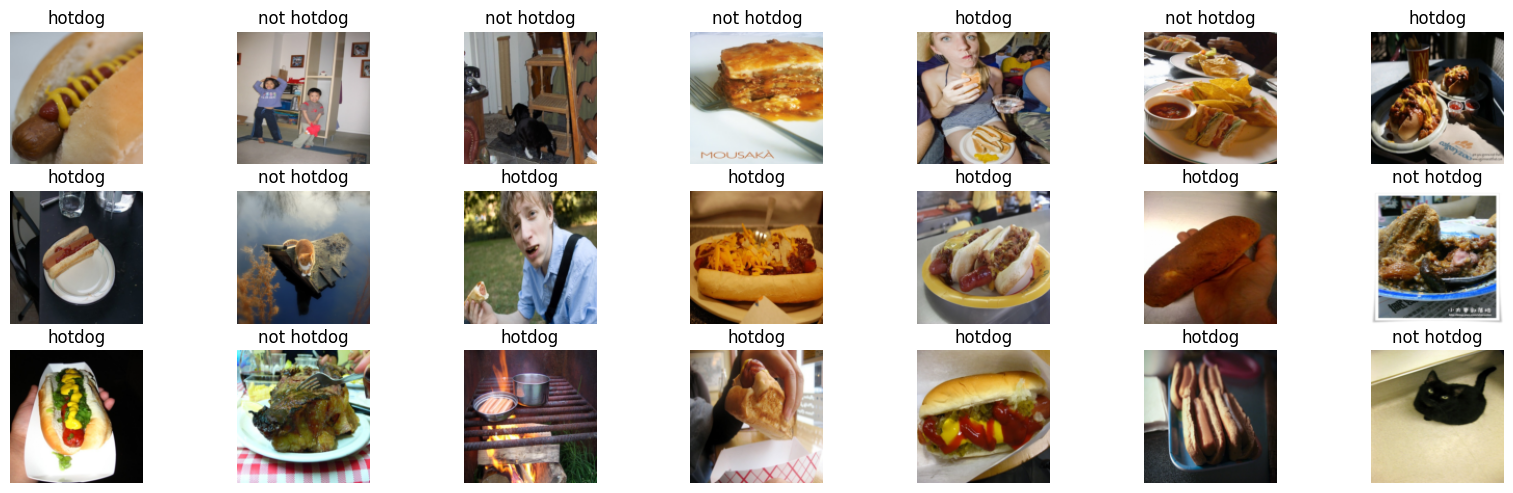

In [40]:
images, labels = next(iter(train_loader))
plt.figure(figsize=(20,10))

for i in range(21):
    plt.subplot(5,7,i+1)
    plt.imshow(np.swapaxes(np.swapaxes(images[i].numpy(), 0, 2), 0, 1))
    plt.title(['hotdog', 'not hotdog'][labels[i].item()])
    plt.axis('off')

    


## Baseline Vision
Now create a model and train it!

Baseline uses only Conv, ReLU, MaxPool and FC (same layer types as the group v1 baseline), one conv per stage, slightly wider channels, and Adam:
* channels $32 \rightarrow 64 \rightarrow 128$, three $2\times 2$ pools ($128\rightarrow 16$)
* flatten $16\times 16\times 128$ then `Linear(32768, 128)` $\rightarrow$ `Linear(128, 2)` logits (no Softmax)
* train with Adam (`lr=0.001`) for 6 epochs


In [41]:
class HotdogBaselineCNN(nn.Module):
    """Same layer types as the group baseline (Conv / ReLU / MaxPool / FC),
    3-stage 128	o16 spatial size. Slightly wider than v1 (32-64-128 vs 16-32-64)."""
    def __init__(self, num_classes=2):
        super(HotdogBaselineCNN, self).__init__()

        self.convolutional = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )

        # 16 x 16 x 128 = 32768
        self.fully_connected = nn.Sequential(
            nn.Linear(16 * 16 * 128, 128),
            nn.ReLU(),
            nn.Linear(128, num_classes),
        )

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
            elif isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.convolutional(x)
        x = x.view(x.size(0), -1)
        x = self.fully_connected(x)
        return x

We instantiate a copy of our network, transfer it to the GPU if it's available.
We also check if the dimensions of our network match.

In [42]:
model = HotdogBaselineCNN(num_classes=2)
model.to(device)
# Adam is what made the group v1 baseline reach ~72%; SGD 0.01 collapses this CNN (~50%)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable parameters: {n_params:,}')

data = next(iter(train_loader))[0].to(device)
print('Shape of the output from the convolutional part', model.convolutional(data).shape)
print('Shape of the model output (logits)', model(data).shape)


# Count trainable parameters
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total Trainable Parameters: {total_params:,}")

# Test forward pass with a dummy batch on device
dummy_x = torch.randn(4, 3, 128, 128, device=device)
dummy_out = model(dummy_x)
print(f"Test forward pass output shape: {dummy_out.shape}  (batch_size=4, num_classes=2)")

Trainable parameters: 4,287,938
Shape of the output from the convolutional part torch.Size([64, 128, 16, 16])
Shape of the model output (logits) torch.Size([64, 2])
Total Trainable Parameters: 4,287,938
Test forward pass output shape: torch.Size([4, 2])  (batch_size=4, num_classes=2)


We train this network for 12 epochs with Adam and record the training curve.

In [43]:
num_epochs = 10
train_accs, test_accs, train_losses = [], [], []
best_test_acc = 0.0

for epoch in tqdm(range(num_epochs), unit='epoch'):
    model.train()
    train_correct = 0
    running_loss = 0.0
    for minibatch_no, (data, target) in tqdm(enumerate(train_loader), total=len(train_loader)):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

        predicted = output.argmax(1)
        train_correct += (target==predicted).sum().cpu().item()
        running_loss += loss.item() * data.size(0)

    model.eval()
    test_correct = 0
    for data, target in test_loader:
        data, target = data.to(device), target.to(device)
        with torch.no_grad():
            output = model(data)
        predicted = output.argmax(1)
        test_correct += (target==predicted).sum().item()
    train_acc = train_correct/len(trainset)
    test_acc = test_correct/len(testset)
    epoch_loss = running_loss / len(trainset)
    train_accs.append(train_acc)
    test_accs.append(test_acc)
    train_losses.append(epoch_loss)
    best_test_acc = max(best_test_acc, test_acc)
    print("Accuracy train: {train:.1f}%\t test: {test:.1f}%\t loss: {loss:.4f}".format(
        test=100*test_acc, train=100*train_acc, loss=epoch_loss))

print(f"Final test accuracy: {100*test_accs[-1]:.1f}%")
print(f"Best test accuracy:  {100*best_test_acc:.1f}%")

  0%|          | 0/10 [00:00<?, ?epoch/s]

  0%|          | 0/32 [00:00<?, ?it/s]

Accuracy train: 57.0%	 test: 68.5%	 loss: 2.5138


  0%|          | 0/32 [00:00<?, ?it/s]

Accuracy train: 72.0%	 test: 71.4%	 loss: 0.5684


  0%|          | 0/32 [00:00<?, ?it/s]

... (11 outputs left out)

  0%|          | 0/32 [00:00<?, ?it/s]

Accuracy train: 93.6%	 test: 71.4%	 loss: 0.1762


  0%|          | 0/32 [00:00<?, ?it/s]

Accuracy train: 96.0%	 test: 73.5%	 loss: 0.1276
Final test accuracy: 73.5%
Best test accuracy:  74.9%


## Squish vs keep-aspect-ratio crop

The course PDF notes that `Resize((128, 128))` forces a square by **squishing** non-square photos, and that this is not necessarily best. We keep the same `HotdogBaselineCNN` + Adam and compare:

* **Squish:** `Resize((128, 128))` — stretches/compresses the whole image (this is also our baseline transform).
* **Crop:** `Resize(128)` then `CenterCrop(128)` — keeps aspect ratio, may cut off the edges.

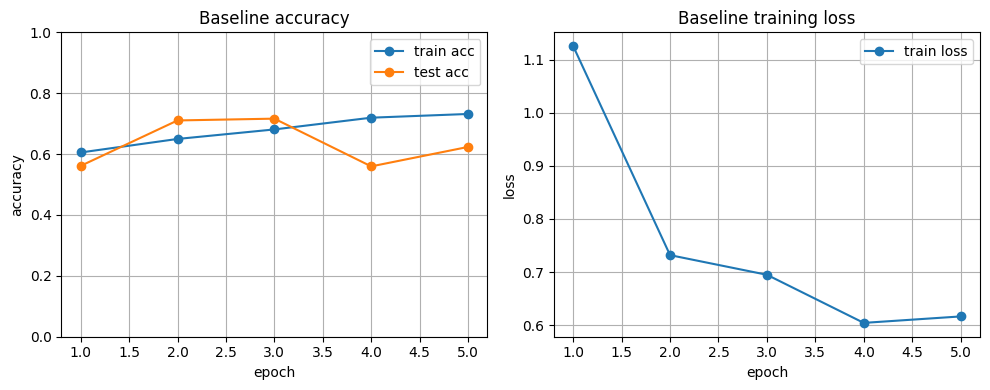

In [21]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, num_epochs + 1), train_accs, marker='o', label='train acc')
plt.plot(range(1, num_epochs + 1), test_accs, marker='o', label='test acc')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.title('Baseline accuracy')

plt.subplot(1, 2, 2)
plt.plot(range(1, num_epochs + 1), train_losses, marker='o', label='train loss')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.grid(True)
plt.title('Baseline training loss')

plt.tight_layout()
plt.show()

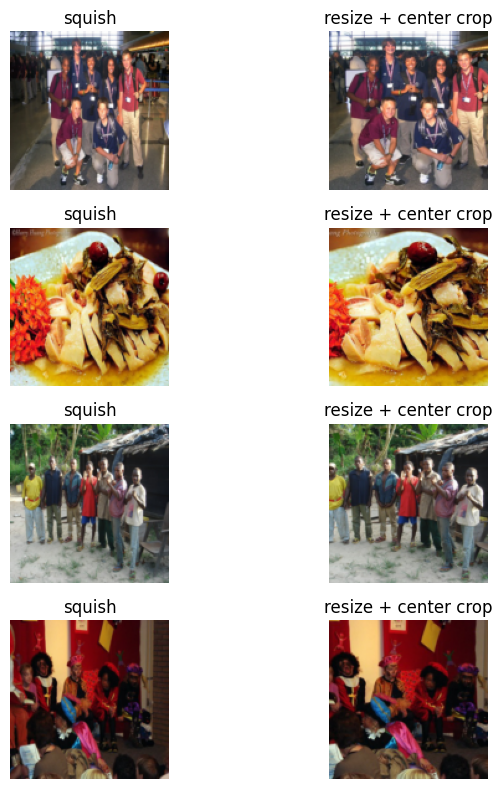

In [ ]:
squish_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor(),
])

#Shrink the shorter side to 128, and scale the other side accordingly while maintaining the original aspect ratio of the image.
crop_transform = transforms.Compose([
    transforms.Resize(size),  # shrink the shorter side to 128
    transforms.CenterCrop(size),  # crop the center 128x128, scale the other side accordingly while maintaining the original aspect ratio of the image.
    transforms.ToTensor(),
])

# Visual check: same files, two ways of making a 128x128 tensor
sample_paths = trainset.image_paths[:4]
plt.figure(figsize=(8, 8))
for i, path in enumerate(sample_paths):
    img = Image.open(path).convert('RGB')
    plt.subplot(4, 2, 2 * i + 1)
    plt.imshow(squish_transform(img).permute(1, 2, 0))
    plt.title('squish')
    plt.axis('off')
    plt.subplot(4, 2, 2 * i + 2)
    plt.imshow(crop_transform(img).permute(1, 2, 0))
    plt.title('resize + center crop')
    plt.axis('off')
plt.tight_layout()
plt.show()

In [30]:
def make_loaders(transform):
    tr = Hotdog_NotHotdog(train=True, transform=transform, data_path=data_path)
    te = Hotdog_NotHotdog(train=False, transform=transform, data_path=data_path)
    tr_loader = DataLoader(tr, batch_size=batch_size, shuffle=True, num_workers=0)
    te_loader = DataLoader(te, batch_size=batch_size, shuffle=False, num_workers=0)
    return tr, te, tr_loader, te_loader


def train_same_baseline(tr_loader, te_loader, tr_set, te_set, epochs):
    net = HotdogBaselineCNN(num_classes=2).to(device)
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    crit = nn.CrossEntropyLoss()
    history = {'train_acc': [], 'test_acc': [], 'train_loss': []}
    best = 0.0
    for epoch in tqdm(range(epochs), unit='epoch'):
        net.train()
        train_correct = 0
        running_loss = 0.0
        for data, target in tr_loader:
            data, target = data.to(device), target.to(device)
            opt.zero_grad()
            output = net(data)
            loss = crit(output, target)
            loss.backward()
            opt.step()
            train_correct += (output.argmax(1) == target).sum().item()
            running_loss += loss.item() * data.size(0)
        net.eval()
        test_correct = 0
        with torch.no_grad():
            for data, target in te_loader:
                data, target = data.to(device), target.to(device)
                output = net(data)
                test_correct += (output.argmax(1) == target).sum().item()
        train_acc = train_correct / len(tr_set)
        test_acc = test_correct / len(te_set)
        epoch_loss = running_loss / len(tr_set)
        history['train_acc'].append(train_acc)
        history['test_acc'].append(test_acc)
        history['train_loss'].append(epoch_loss)
        best = max(best, test_acc)
        print(f'epoch {epoch+1}/{epochs}  train {100*train_acc:.1f}%  test {100*test_acc:.1f}%  loss {epoch_loss:.4f}')
    history['best_test'] = best
    history['final_test'] = history['test_acc'][-1]
    return net, history

In [31]:
resize_epochs = num_epochs  # same length as the baseline run above

print('=== SQUISH: Resize((128, 128)) ===')
squish_train, squish_test, squish_tr_loader, squish_te_loader = make_loaders(squish_transform)
_, hist_squish = train_same_baseline(
    squish_tr_loader, squish_te_loader, squish_train, squish_test, resize_epochs)

print('\n=== CROP: Resize(128) + CenterCrop(128) ===')
crop_train, crop_test, crop_tr_loader, crop_te_loader = make_loaders(crop_transform)
_, hist_crop = train_same_baseline(
    crop_tr_loader, crop_te_loader, crop_train, crop_test, resize_epochs)

print('\n=== Comparison (same CNN, Adam, epochs) ===')
print(f"Squish  final test {100*hist_squish['final_test']:.1f}%  best {100*hist_squish['best_test']:.1f}%")
print(f"Crop    final test {100*hist_crop['final_test']:.1f}%  best {100*hist_crop['best_test']:.1f}%")

=== SQUISH: Resize((128, 128)) ===


  0%|          | 0/6 [00:00<?, ?epoch/s]

epoch 1/6  train 57.0%  test 68.5%  loss 1.9425
epoch 2/6  train 74.0%  test 71.8%  loss 0.5352
epoch 3/6  train 79.4%  test 71.6%  loss 0.4564
epoch 4/6  train 83.5%  test 74.2%  loss 0.3836
epoch 5/6  train 85.8%  test 75.2%  loss 0.3222
epoch 6/6  train 90.5%  test 75.5%  loss 0.2467

=== CROP: Resize(128) + CenterCrop(128) ===


  0%|          | 0/6 [00:00<?, ?epoch/s]

epoch 1/6  train 61.6%  test 69.5%  loss 1.4586
epoch 2/6  train 74.5%  test 72.7%  loss 0.5309
epoch 3/6  train 78.0%  test 73.0%  loss 0.4773
epoch 4/6  train 81.8%  test 74.4%  loss 0.4212
epoch 5/6  train 84.8%  test 72.1%  loss 0.3585
epoch 6/6  train 86.7%  test 74.7%  loss 0.3264

=== Comparison (same CNN, Adam, epochs) ===
Squish  final test 75.5%  best 75.5%
Crop    final test 74.7%  best 74.7%


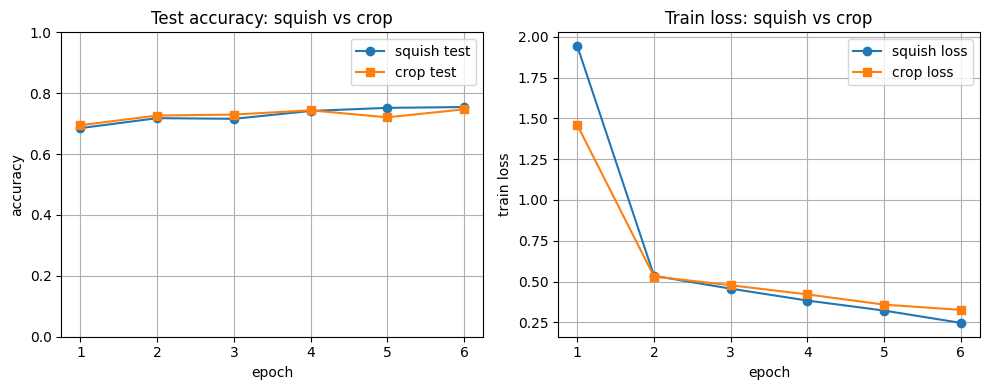

In [32]:
epochs_axis = range(1, resize_epochs + 1)
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_axis, hist_squish['test_acc'], marker='o', label='squish test')
plt.plot(epochs_axis, hist_crop['test_acc'], marker='s', label='crop test')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.title('Test accuracy: squish vs crop')

plt.subplot(1, 2, 2)
plt.plot(epochs_axis, hist_squish['train_loss'], marker='o', label='squish loss')
plt.plot(epochs_axis, hist_crop['train_loss'], marker='s', label='crop loss')
plt.xlabel('epoch')
plt.ylabel('train loss')
plt.legend()
plt.grid(True)
plt.title('Train loss: squish vs crop')
plt.tight_layout()
plt.show()